Importing Libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
import numpy as np
from scipy import ndimage
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from google.colab.patches import cv2_imshow
from PIL import Image
from mtcnn.mtcnn import MTCNN
image = cv2.imread("/content/Jabez Solomon - Photo.jpeg")

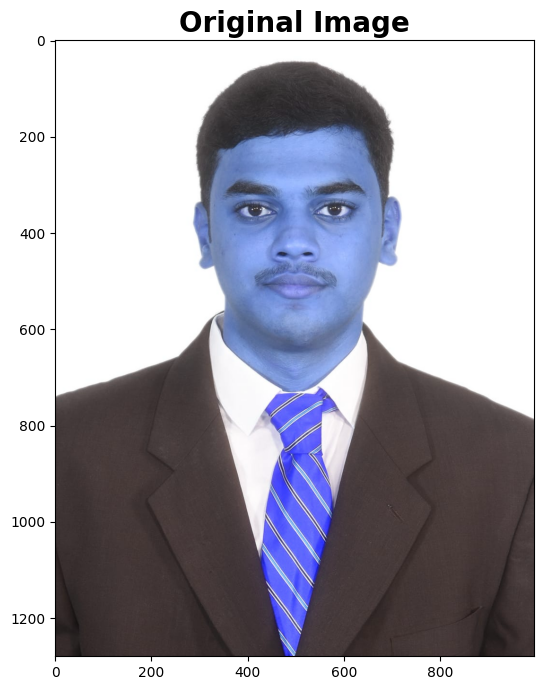

In [ ]:
# Displaying the Image using Matplotlib
plt.figure(figsize=(10, 8))
plt.title('Original Image',fontsize=20,fontweight='bold')
plt.imshow(image)

In [ ]:
type(image)

numpy.ndarray

In [ ]:
image.shape

(1280, 995, 3)

In [ ]:
image.ndim

3

SOBEL EDGE OPERATOR - First-Order Edge Operator

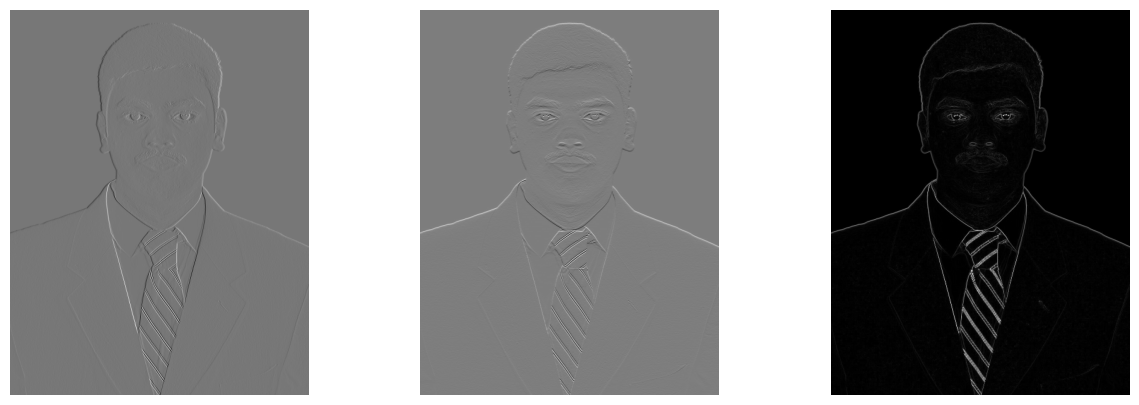

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Function to convert an RGB image to grayscale
def rgb_to_grayscale(img):
    return np.dot(img[..., :3], [0.2989, 0.5870, 0.1140]).astype(np.uint8)

# Function to apply a convolution filter manually
def convolve2d(image, kernel):
    image_h, image_w = image.shape
    kernel_h, kernel_w = kernel.shape
    output_h = image_h - kernel_h + 1
    output_w = image_w - kernel_w + 1
    new_image = np.zeros((output_h, output_w)).astype(np.float32)
    for y in range(0, output_h):
        for x in range(0, output_w):
            new_image[y, x] = np.sum(image[y:y+kernel_h, x:x+kernel_w] * kernel).astype(np.float32)
    return new_image

# Function to resize an image manually to 50% of its original size
def resize_image(image, scale_percent=50):
    new_width = int(image.shape[1] * scale_percent / 100)
    new_height = int(image.shape[0] * scale_percent / 100)
    new_image = np.zeros((new_height, new_width), dtype=np.float32)
    y_scale_factor = image.shape[0] / float(new_height)
    x_scale_factor = image.shape[1] / float(new_width)
    for y in range(new_height):
        for x in range(new_width):
            new_image[y, x] = image[int(y * y_scale_factor), int(x * x_scale_factor)]
    return new_image

# Sobel filters
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
sobel_y = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]])

# Convert the image to grayscale
gray_image = rgb_to_grayscale(image)

# Apply Sobel filters to the grayscale image
sobel_x_result = convolve2d(gray_image, sobel_x)
sobel_y_result = convolve2d(gray_image, sobel_y)

# Combined X and Y Sobel Edge Detection
sobel_combined = np.sqrt(np.square(sobel_x_result) + np.square(sobel_y_result))

# Resize the images to a smaller size (e.g., 50% of the original size)
sobel_x_resized = resize_image(sobel_x_result)
sobel_y_resized = resize_image(sobel_y_result)
sobel_combined_resized = resize_image(sobel_combined)

# Display the results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(sobel_x_resized, cmap='gray')
axes[0].axis('off')
axes[1].imshow(sobel_y_resized, cmap='gray')
axes[1].axis('off')
axes[2].imshow(sobel_combined_resized, cmap='gray')
axes[2].axis('off')
plt.show()


Prewitt Edge - First-Order Edge Operator

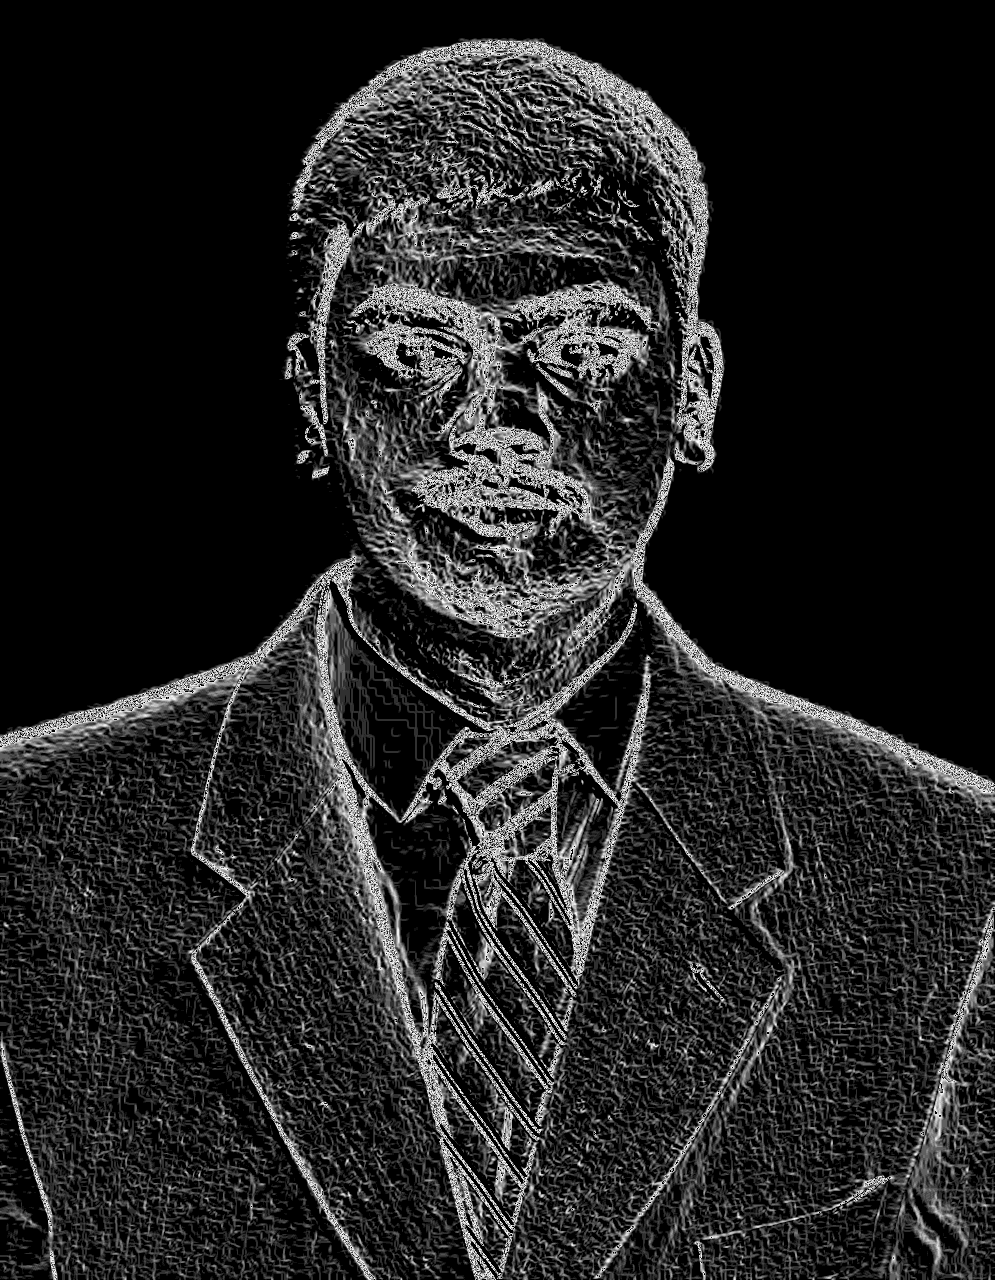

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Load the image in grayscale
image = cv2.imread('/content/Jabez Solomon - Photo.jpeg', cv2.IMREAD_GRAYSCALE)

# Apply Gaussian blur to reduce noise
blurred_image = cv2.GaussianBlur(image, (5, 5), 0)

# Define the Prewitt kernels for gradient calculation
prewitt_x = np.array([[-1, 0, 1],
                      [-1, 0, 1],
                      [-1, 0, 1]])

prewitt_y = np.array([[1, 1, 1],
                      [0, 0, 0],
                      [-1, -1, -1]])

# Convolve the blurred image with Prewitt operators
gradient_x = cv2.filter2D(blurred_image, -1, prewitt_x)
gradient_y = cv2.filter2D(blurred_image, -1, prewitt_y)

# Calculate gradient magnitude
gradient_magnitude = np.sqrt(gradient_x**2 + gradient_y**2)

# Normalize the gradient magnitude manually to the range [0, 255]
gradient_magnitude = ((gradient_magnitude - gradient_magnitude.min()) / (gradient_magnitude.max() - gradient_magnitude.min()) * 255).astype(np.uint8)

# Display the Prewitt edge detection result
cv2_imshow(gradient_magnitude)


CANNY EDGE DETECTION - First-order edge detection

Text(0.5, 1.0, 'CANNY EDGE')

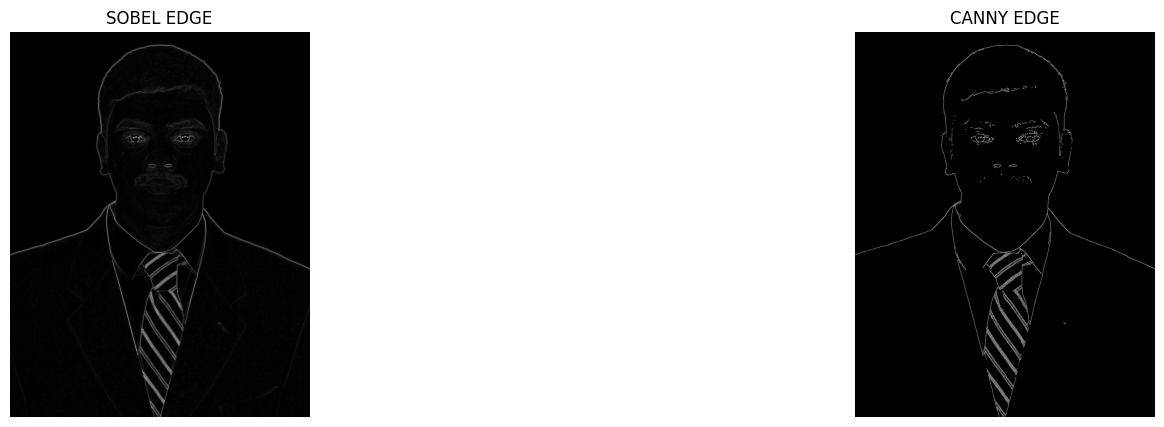

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Function to convert an RGB image to grayscale
def rgb_to_grayscale(img):
    return np.dot(img[..., :3], [0.2989, 0.5870, 0.1140]).astype(np.uint8)

# Function to apply a convolution filter manually
def convolve2d(image, kernel):
    image_h, image_w = image.shape
    kernel_h, kernel_w = kernel.shape
    output_h = image_h - kernel_h + 1
    output_w = image_w - kernel_w + 1
    new_image = np.zeros((output_h, output_w)).astype(np.float32)
    for y in range(0, output_h):
        for x in range(0, output_w):
            new_image[y, x] = np.sum(image[y:y+kernel_h, x:x+kernel_w] * kernel).astype(np.float32)
    return new_image

# Function to resize an image manually to 50% of its original size
def resize_image(image, scale_percent=50):
    new_width = int(image.shape[1] * scale_percent / 100)
    new_height = int(image.shape[0] * scale_percent / 100)
    new_image = np.zeros((new_height, new_width), dtype=np.float32)
    y_scale_factor = image.shape[0] / float(new_height)
    x_scale_factor = image.shape[1] / float(new_width)
    for y in range(new_height):
        for x in range(new_width):
            new_image[y, x] = image[int(y * y_scale_factor), int(x * x_scale_factor)]
    return new_image

# Function for non-maximum suppression
def non_max_suppression(gradient_magnitude, gradient_direction):
    suppressed = np.zeros_like(gradient_magnitude)
    angle_quantized = np.round(gradient_direction * (4.0 / np.pi)) % 4
    for i in range(1, gradient_magnitude.shape[0]-1):
        for j in range(1, gradient_magnitude.shape[1]-1):
            if angle_quantized[i, j] == 0:
                suppressed[i, j] = gradient_magnitude[i, j] if (gradient_magnitude[i, j] > gradient_magnitude[i, j+1] and gradient_magnitude[i, j] > gradient_magnitude[i, j-1]) else 0
            elif angle_quantized[i, j] == 1:
                suppressed[i, j] = gradient_magnitude[i, j] if (gradient_magnitude[i, j] > gradient_magnitude[i-1, j+1] and gradient_magnitude[i, j] > gradient_magnitude[i+1, j-1]) else 0
            elif angle_quantized[i, j] == 2:
                suppressed[i, j] = gradient_magnitude[i, j] if (gradient_magnitude[i, j] > gradient_magnitude[i-1, j] and gradient_magnitude[i, j] > gradient_magnitude[i+1, j]) else 0
            elif angle_quantized[i, j] == 3:
                suppressed[i, j] = gradient_magnitude[i, j] if (gradient_magnitude[i, j] > gradient_magnitude[i-1, j-1] and gradient_magnitude[i, j] > gradient_magnitude[i+1, j+1]) else 0
    return suppressed

# Function for thresholding
def thresholding(image, low_threshold, high_threshold):
    strong_edges = (image > high_threshold)
    weak_edges = (image >= low_threshold) & (image <= high_threshold)
    return strong_edges, weak_edges

# Function for hysteresis thresholding
def hysteresis_thresholding(image, strong_edges, weak_edges):
    final_edges = np.zeros_like(image, dtype=np.uint8)
    final_edges[strong_edges] = 255
    for i in range(1, image.shape[0]-1):
        for j in range(1, image.shape[1]-1):
            if weak_edges[i, j]:
                if np.any(strong_edges[i-1:i+2, j-1:j+2]):
                    final_edges[i, j] = 255
    return final_edges

# Load the image
image = plt.imread('/content/Jabez Solomon - Photo.jpeg')

# Convert the image to grayscale
gray_image = rgb_to_grayscale(image)

# Sobel filters
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
sobel_y = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]])

# Apply Sobel filters to the grayscale image
sobel_x_result = convolve2d(gray_image, sobel_x)
sobel_y_result = convolve2d(gray_image, sobel_y)

# Combined X and Y Sobel Edge Detection
sobel_combined = np.sqrt(np.square(sobel_x_result) + np.square(sobel_y_result))

# Non-maximum suppression
sobel_suppressed = non_max_suppression(sobel_combined, np.arctan2(sobel_y_result, sobel_x_result))

# Thresholding
strong_edges, weak_edges = thresholding(sobel_suppressed, 50, 150)

# Hysteresis thresholding
final_edges = hysteresis_thresholding(sobel_suppressed, strong_edges, weak_edges)

# Display the results
fig, axes = plt.subplots(1, 2, figsize=(20, 5))
axes[0].imshow(sobel_combined, cmap='gray')
axes[0].axis('off')
axes[0].set_title("SOBEL EDGE")
axes[1].imshow(final_edges, cmap='gray')
axes[1].axis('off')
axes[1].set_title("CANNY EDGE")

ROBERT EDGE DETECTION - First-Order Edge Operator

In [ ]:
def roberts_edge_detection(image):
    # Roberts operator kernels
    kernel_x = np.array([[1, 0],
                         [0, -1]])
    kernel_y = np.array([[0, 1],
                         [-1, 0]])
    # Convolve image with kernels
    gradient_x = cv2.filter2D(image, -1, kernel_x)
    gradient_y = cv2.filter2D(image, -1, kernel_y)
    # Compute the magnitude of gradients
    gradient_magnitude = np.sqrt(gradient_x**2 + gradient_y**2)
    return gradient_magnitude

# Load the image
image = cv2.imread('/content/Jabez Solomon - Photo.jpeg', cv2.IMREAD_GRAYSCALE)

# Apply Roberts edge detection
roberts_edges = roberts_edge_detection(image)

# Brighten the Roberts edge-detected image
brightened_image = roberts_edges + 100

# Save the brightened Roberts edge-detected image
cv2.imwrite('Brightened_Roberts_Edge_Detected_Image.jpg', brightened_image)

True

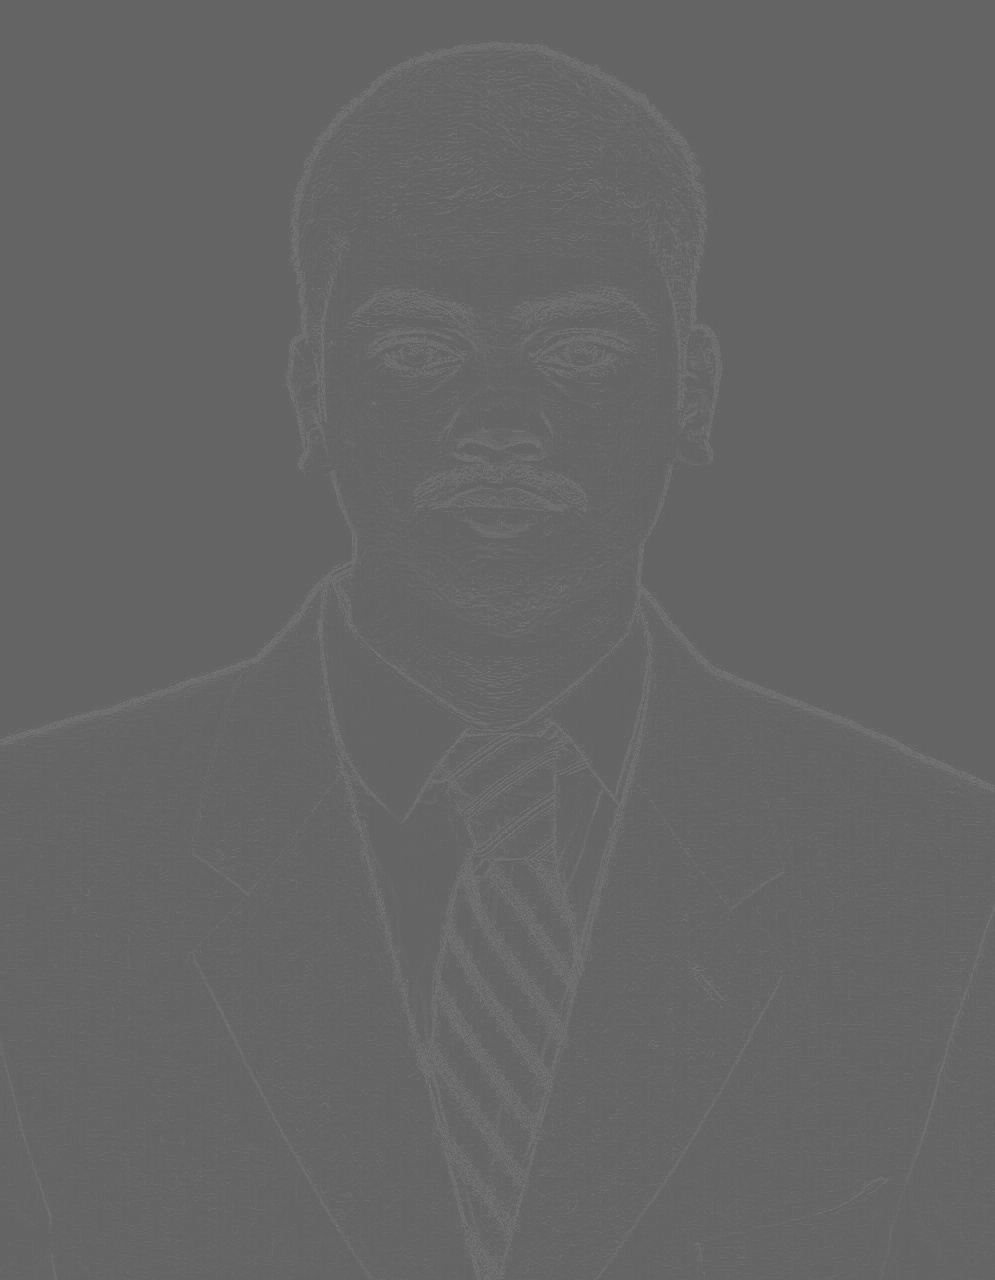

In [ ]:
from IPython.display import display
from PIL import Image

# Load the image
image = Image.open('/content/Brightened_Roberts_Edge_Detected_Image.jpg')

# Display the image
display(image)


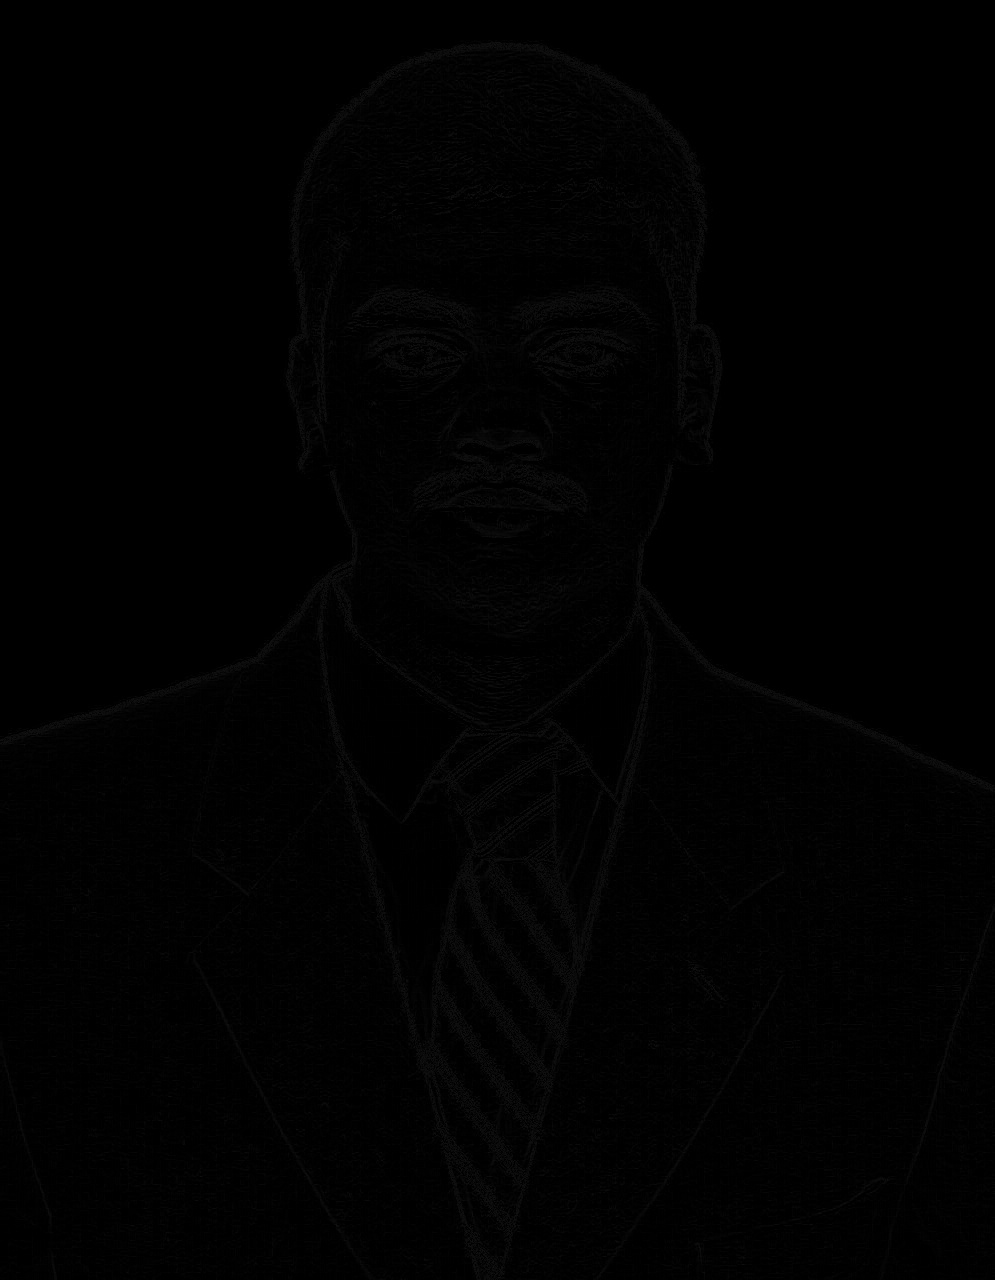

In [ ]:
from IPython.display import display
from PIL import Image

# Load the image
image = Image.open('/content/Roberts_Edge_Detected_Image.jpg')

# Display the image
display(image)

Heatmaps: Generate and overlay heatmaps on images to represent intensity or density information:

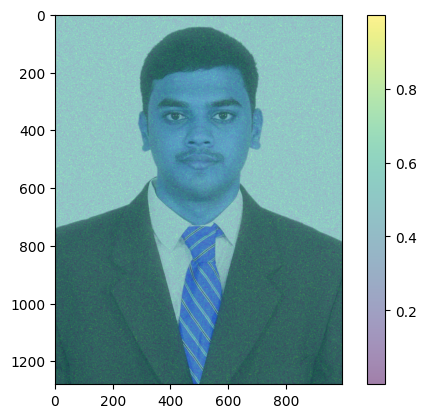

In [ ]:
image = cv2.imread('/content/Jabez Solomon - Photo.jpeg', cv2.IMREAD_COLOR)

# Create a heatmap data
heatmap = np.random.rand(image.shape[0], image.shape[1])

# Overlay the heatmap on the image
plt.imshow(image)
plt.imshow(heatmap, alpha=0.5, cmap='viridis', interpolation='bilinear')
plt.colorbar()
plt.show()


IMAGE SEGMENTATION

In [ ]:
import cv2
import dlib

# Load the pre-trained DLIB models for face detection and facial landmark detection
detector = dlib.get_frontal_face_detector()
predictor = dlib.shape_predictor("/content/shape_predictor_68_face_landmarks (1).dat")  # Download this file from the DLIB website

# Load the image
image = cv2.imread('/content/Jabez Solomon - Photo.jpeg')  # Replace with the path to your image

# Convert the image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Detect faces in the grayscale image
faces = detector(gray)

# Iterate through each detected face
for face in faces:
    # Extract the bounding box of the face
    x, y, w, h = face.left(), face.top(), face.width(), face.height()

    # Draw the bounding box around the face
    cv2.rectangle(image, (x, y), (x + w, y + h), (0, 255, 0), 2)

    # Detect facial landmarks in the face region
    landmarks = predictor(gray, face)

    # Extract the coordinates of specific facial features (e.g., eyes, ears, nose)
    left_eye_pts = [(landmarks.part(i).x, landmarks.part(i).y) for i in range(36, 42)]
    right_eye_pts = [(landmarks.part(i).x, landmarks.part(i).y) for i in range(42, 48)]
    nose_pts = [(landmarks.part(i).x, landmarks.part(i).y) for i in range(27, 36)]

    # Draw polygons around the segmented facial features
    left_eye_pts = np.array(left_eye_pts)
    right_eye_pts = np.array(right_eye_pts)
    nose_pts = np.array(nose_pts)

    cv2.polylines(image, [left_eye_pts], isClosed=True, color=(0, 255, 0), thickness=2)
    cv2.polylines(image, [right_eye_pts], isClosed=True, color=(0, 255, 0), thickness=2)
    cv2.polylines(image, [nose_pts], isClosed=True, color=(255, 0, 0), thickness=2)

# Display the image with detected faces and segmented facial features
cv2.imwrite('Facial_Feature_Segmentation.jpg', image)
cv2.waitKey(0)
cv2.destroyAllWindows()

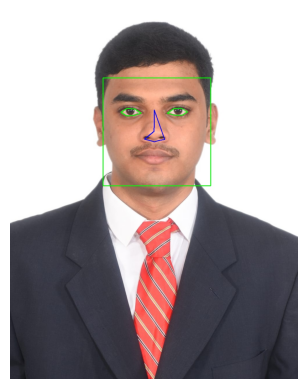

In [ ]:
import matplotlib.pyplot as plt
import cv2

# Load an image
image = cv2.imread('/content/Facial_Feature_Segmentation.jpg')

# Convert from BGR to RGB (Matplotlib uses RGB)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display the image
plt.imshow(image_rgb)
plt.axis('off')  # Turn off axis numbers and ticks
plt.show()


Segmenting face using SVM approach.

In [ ]:
import cv2
import numpy as np
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from skimage.feature import hog
import os

# Function to read images from a folder
def read_images_from_folder(folder_path):
    images = []
    for filename in os.listdir(folder_path):
        if filename.endswith('.jpg') or filename.endswith('.jpeg'):
            image = cv2.imread(os.path.join(folder_path, filename))
            if image is not None:
                images.append(image)
    return images

# Function to extract HOG features from an image patch
def extract_hog_features(patch):
    # Convert patch to grayscale
    patch_gray = cv2.cvtColor(patch, cv2.COLOR_BGR2GRAY)
    # Compute HOG features
    features = hog(patch_gray, orientations=9, pixels_per_cell=(8, 8),
                   cells_per_block=(2, 2), block_norm='L2-Hys')
    # Return HOG features
    return features

# Path to the folders containing positive and negative images
positive_folder = '/content/Positive'
negative_folder = '/content/Negative'

# Read positive and negative images from folders
positive_patches = read_images_from_folder(positive_folder)
negative_patches = read_images_from_folder(negative_folder)

# Check the number of positive and negative patches
print("Number of positive patches:", len(positive_patches))
print("Number of negative patches:", len(negative_patches))

# Example of the first positive patch
print("Shape of the first positive patch:", positive_patches[0].shape)

# Example of the first negative patch
print("Shape of the first negative patch:", negative_patches[0].shape)

# Example of the first positive patch after resizing
resized_positive_patch = cv2.resize(positive_patches[0], (100, 100))
print("Shape of the resized positive patch:", resized_positive_patch.shape)

# Example of the first negative patch after resizing
resized_negative_patch = cv2.resize(negative_patches[0], (100, 100))
print("Shape of the resized negative patch:", resized_negative_patch.shape)

# Extract HOG features from positive and negative patches
positive_features = [extract_hog_features(patch) for patch in positive_patches]
negative_features = [extract_hog_features(patch) for patch in negative_patches]

# Resize positive patches to a fixed size
resized_positive_patches = [cv2.resize(patch, (100, 100)) for patch in positive_patches]

# Resize negative patches to a fixed size
resized_negative_patches = [cv2.resize(patch, (100, 100)) for patch in negative_patches]

# Extract HOG features from positive and negative patches
positive_features = [extract_hog_features(patch) for patch in resized_positive_patches]
negative_features = [extract_hog_features(patch) for patch in resized_negative_patches]

# Combine positive and negative features and labels
X = np.concatenate((positive_features, negative_features))
y = np.hstack((np.ones(len(positive_features)), np.zeros(len(negative_features))))


# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train SVM classifier
svm_classifier = SVC(kernel='linear')
svm_classifier.fit(X_train, y_train)

# Evaluate classifier
accuracy = svm_classifier.score(X_test, y_test)
print("Accuracy:", accuracy)


Number of positive patches: 26
Number of negative patches: 21
Shape of the first positive patch: (1623, 1000, 3)
Shape of the first negative patch: (256, 256, 3)
Shape of the resized positive patch: (100, 100, 3)
Shape of the resized negative patch: (100, 100, 3)
Accuracy: 1.0


1. Number of positive patches: There are 26 positive patches (images of faces).
2. Number of negative patches: There are 21 negative patches (images of non-faces).
3. Shape of the first positive patch: The dimensions of the first positive patch are (1623, 1000, 3), indicating a color image with a height of 1623 pixels, width of 1000 pixels, and 3 color channels (RGB).
4. Shape of the first negative patch: The dimensions of the first negative patch are (256, 256, 3), indicating a color image with a height and width of 256 pixels and 3 color channels (RGB).
5. Shape of the resized positive patch: After resizing, all positive patches have been resized to a fixed size of (100, 100, 3), indicating a color image with a height and width of 100 pixels and 3 color channels (RGB).
6. Shape of the resized negative patch: Similarly, all negative patches have been resized to the same fixed size of (100, 100, 3).
7. Accuracy: The accuracy of the trained SVM classifier on the test data is 1.0, indicating perfect classification performance on the test set.

Segmenting face using K-Means cluster approach

In [ ]:
import cv2
import numpy as np

# Load an image
image = cv2.imread('/content/Jabez Solomon - Photo.jpeg')

# Convert the image to RGB format
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Reshape the image to a 2D array of pixels and 3 color values (RGB)
pixel_values = image.reshape((-1, 3))

# Convert to float
pixel_values = np.float32(pixel_values)

# Define stopping criteria
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)#inertia of initial ones

# Number of clusters (K)
k = 3

# Perform K-means clustering
_, labels, (centers) = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

# Convert back to 8-bit pixel values
centers = np.uint8(centers)

# Flatten the labels array
labels = labels.flatten()

# Create the segmented image
segmented_image = centers[labels.flatten()]

# Reshape back to the original image dimension
segmented_image = segmented_image.reshape(image.shape)

# Convert the segmented image to grayscale
segmented_gray = cv2.cvtColor(segmented_image, cv2.COLOR_RGB2GRAY)

# Apply threshold to the segmented image
_, segmented_thresh = cv2.threshold(segmented_gray, 127, 255, cv2.THRESH_BINARY)

# Apply edge detection using the Canny method with adjustable thickness
edges = cv2.Canny(segmented_thresh, 100, 200, apertureSize=3)

# Save the edge image as a PNG file
cv2.imwrite('edges0.png', edges)

# Display the original image, segmented image, thresholded image, and edge detected image
cv2.imwrite('edges24.png',image)
cv2.imwrite('edges34.png',segmented_image)
cv2.imwrite('edges44.png',  segmented_thresh)

# Wait for a key press and close the image window
cv2.waitKey(0)
cv2.destroyAllWindows()

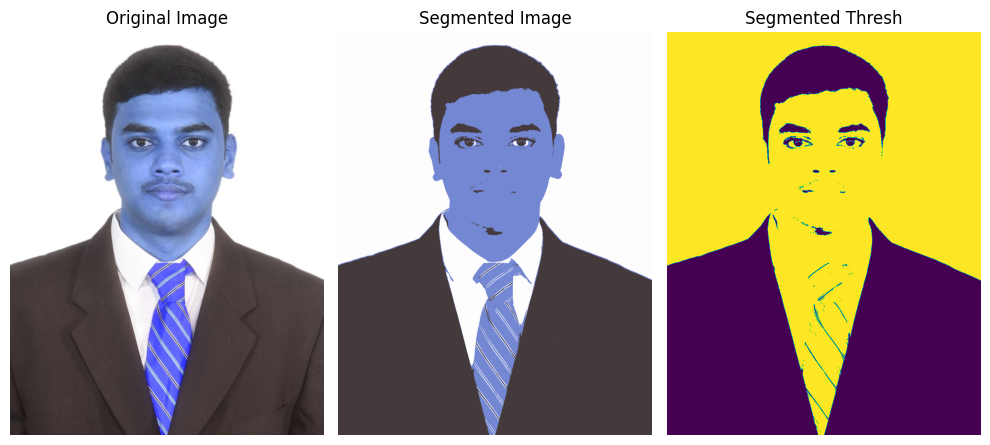

In [ ]:
import matplotlib.pyplot as plt

# Read the images
edges24 = plt.imread('/content/edges24.png')
edges34 = plt.imread('/content/edges34.png')
edges44 = plt.imread('/content/edges44.png')

# Display the images
plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.imshow(edges24)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(edges34)
plt.title('Segmented Image')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(edges44)
plt.title('Segmented Thresh')
plt.axis('off')

plt.tight_layout()
plt.show()


Segmenting face using deep learning techniques - MTCNN

---



In [ ]:
image = cv2.imread('/content/Jabez Solomon - Photo.jpeg')
image = cv2.cvtColor(image,cv2.COLOR_RGB2BGR)

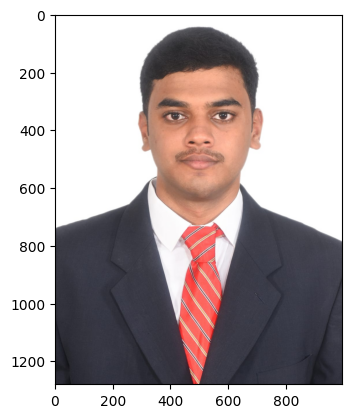

In [ ]:
plt.imshow(image)
model = MTCNN()
print(model)

In [ ]:
output = model.detect_faces(image)
output
face_count = len(output)
face_count

1/1 [==============================] - 0s 338ms/step


1

In [ ]:
for i in range(0,face_count):
    box = output[i]['box']
    conf = output[i]['confidence']
    print(box)
    print(conf)
    if conf > 0.6:
        cv2.rectangle(image,(box[0],box[1]),(box[0]+box[2],box[1]+box[3]),(0,255,0),6)
#cv2.rectangle(image_to_be_drawn_upon,(X),(Y),RGB,thickness)

[326, 164, 341, 452]
0.9999919533729553


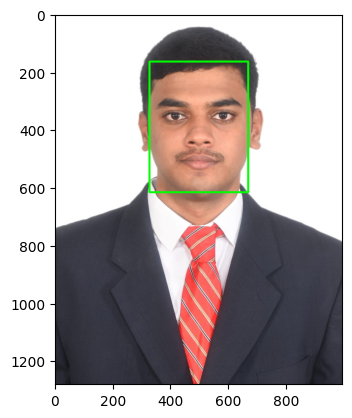

In [ ]:
plt.imshow(image)

Any other features that students learned by yourselves


Title: Combining Laplacian of Gaussian and Harris Corner Detector for Feature Detection - Second-Order Edge Operators

Introduction:
Feature detection is a crucial step in image processing and computer vision tasks. It involves identifying and extracting key points or regions in an image that can be used for further analysis, such as object recognition, image alignment, and scene understanding. In this report, we explore the combination of two popular feature detection techniques: the Laplacian of Gaussian (LoG) operation and the Harris corner detector.

Methods:

Laplacian of Gaussian (LoG) Operation:

The LoG operation is a multi-step process that enhances edges and details in an image by convolving the image with a Gaussian smoothing kernel followed by a Laplacian filter.
We first load the input grayscale image and define parameters for the Gaussian smoothing (filter size and standard deviation).
Next, we create a 2D Gaussian kernel and apply it to the image using the cv2.filter2D function to obtain a smoothed image.
Then, we define a Laplacian kernel and apply it to the smoothed image to compute the LoG result.
Harris Corner Detector:

The Harris corner detector is a corner detection algorithm that identifies corner points in an image based on local intensity variations.
We apply the Harris corner detector to the output of the LoG operation to detect corners in the image.
Detected corner points are marked in white on a copy of the original grayscale image.
Results:

The output of the Harris corner detector is displayed, showing the detected corner points in the input image.
Discussion:

Combining the LoG operation with the Harris corner detector enhances the detection of corners in the image by first enhancing edges and then identifying corners based on local intensity changes.
This approach can be useful in various computer vision applications, such as image registration, object detection, and motion tracking, where accurate feature detection is essential.
Conclusion:

The combination of the LoG operation and the Harris corner detector provides a robust method for feature detection in images, enabling the extraction of key points that can be used for further analysis and processing.

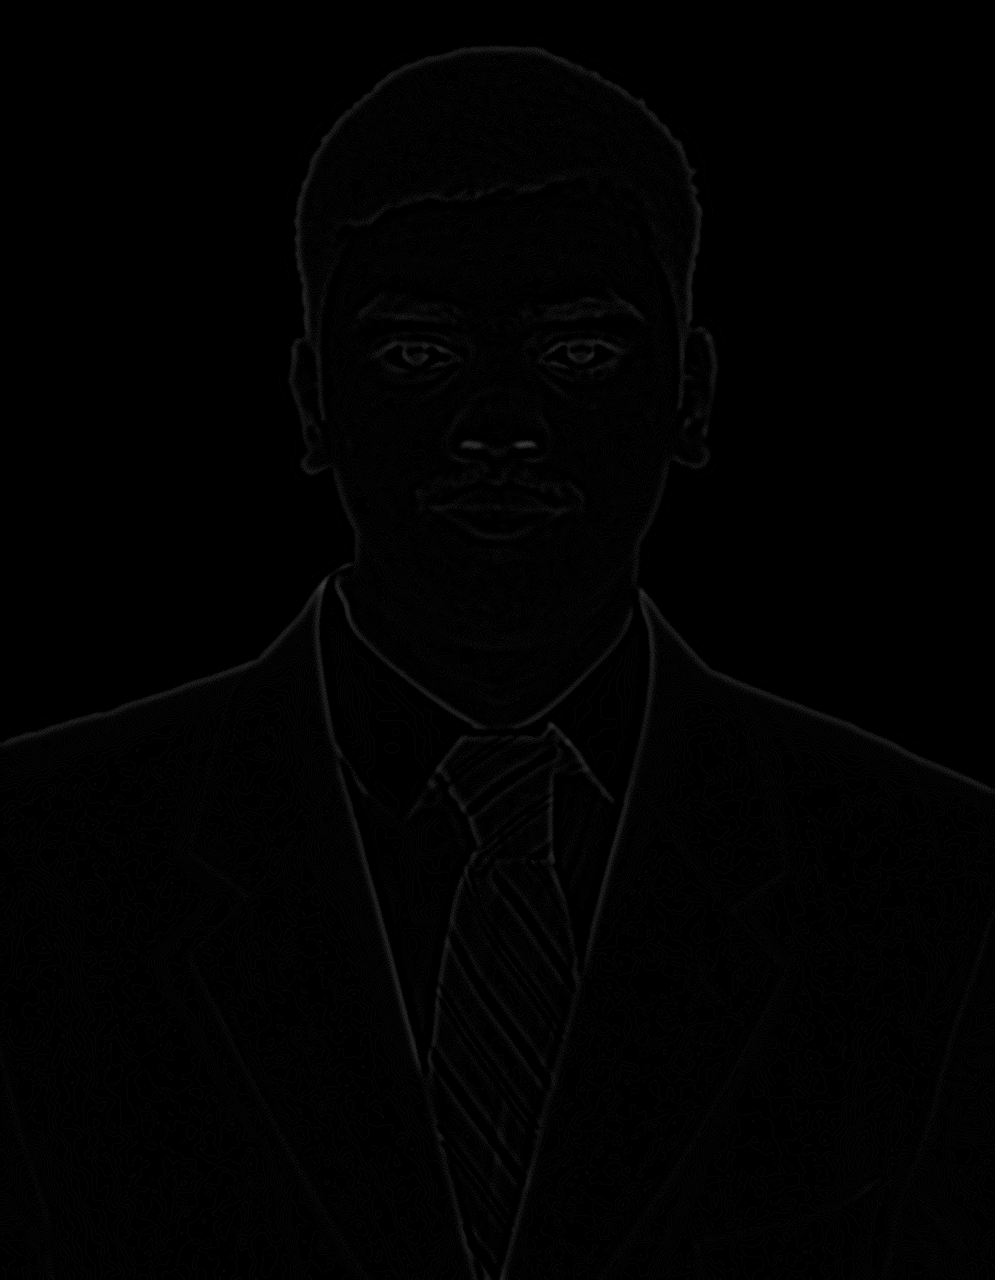

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Load the image in grayscale
image = cv2.imread('/content/Jabez Solomon - Photo.jpeg', cv2.IMREAD_GRAYSCALE)

# Define the size of the LoG filter (17x17)
filter_size = (17, 17)

# Define the standard deviation (sigma) for the Gaussian smoothing
sigma = 3.0

# Create a 2D Gaussian kernel
x, y = np.meshgrid(np.arange(-filter_size[0] // 2 + 1, filter_size[0] // 2 + 1),
                   np.arange(-filter_size[1] // 2 + 1, filter_size[1] // 2 + 1))
gaussian_kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))

# Normalize the Gaussian kernel
gaussian_kernel /= np.sum(gaussian_kernel)

# Apply the Gaussian smoothing to the image
smoothed_image = cv2.filter2D(image, -1, gaussian_kernel)

# Create the Laplacian kernel
laplacian_kernel = np.array([[0, 0, 1, 0, 0],
                             [0, 1, 2, 1, 0],
                             [1, 2, -16, 2, 1],
                             [0, 1, 2, 1, 0],
                             [0, 0, 1, 0, 0]])

# Apply the Laplacian filter to the smoothed image
log_result = cv2.filter2D(smoothed_image, -1, laplacian_kernel)

# Display the Laplacian of Gaussian result
cv2_imshow(log_result)


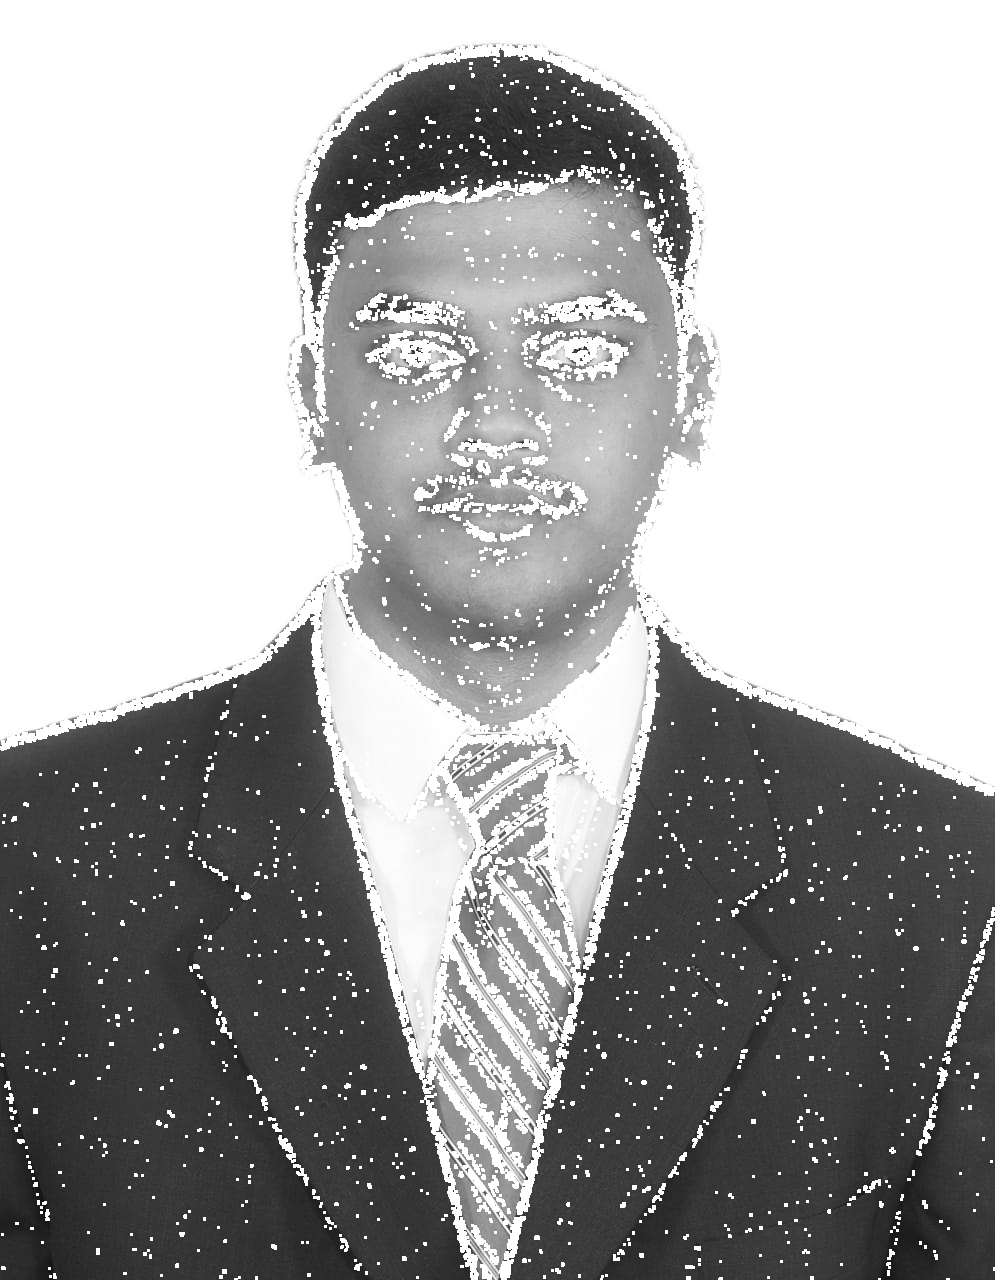

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Load the image in grayscale
image = cv2.imread('/content/Jabez Solomon - Photo.jpeg', cv2.IMREAD_GRAYSCALE)

# Define the size of the LoG filter (17x17)
filter_size = (17, 17)

# Define the standard deviation (sigma) for the Gaussian smoothing
sigma = 3.0

# Create a 2D Gaussian kernel
x, y = np.meshgrid(np.arange(-filter_size[0] // 2 + 1, filter_size[0] // 2 + 1),
                   np.arange(-filter_size[1] // 2 + 1, filter_size[1] // 2 + 1))
gaussian_kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))

# Normalize the Gaussian kernel
gaussian_kernel /= np.sum(gaussian_kernel)

# Apply the Gaussian smoothing to the image
smoothed_image = cv2.filter2D(image, -1, gaussian_kernel)

# Create the Laplacian kernel
laplacian_kernel = np.array([[0, 0, 1, 0, 0],
                             [0, 1, 2, 1, 0],
                             [1, 2, -16, 2, 1],
                             [0, 1, 2, 1, 0],
                             [0, 0, 1, 0, 0]])

# Apply the Laplacian filter to the smoothed image
log_result = cv2.filter2D(smoothed_image, -1, laplacian_kernel)

# Harris Corner Detection
harris_corners = cv2.cornerHarris(log_result, blockSize=2, ksize=3, k=0.04)
harris_corners = cv2.dilate(harris_corners, None)

# Threshold the corner response
threshold = 0.01 * harris_corners.max()
corner_image = image.copy()
corner_image[harris_corners > threshold] = 255  # Mark detected corners in white

# Display the detected corners
cv2_imshow(corner_image)
